In [ ]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load Dataset
df = pd.read_csv("heart.csv")

In [22]:
# Chk dataset
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types & missing values:")
print(df.info())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nMissing values per column:")
print(df.isnull().sum())

print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", len(df) - df.duplicated().sum())

Shape (rows, columns): (1025, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types & missing values:
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   float64
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   float64
 4   chol      1025 non-null   float64
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   float64
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(5), int64(9)
memory usage: 112.2 KB
None

Total missing values

In [4]:
# Chk Class Imlanace
print("\nClass counts:")
print(df['target'].value_counts())
print("\nClass percentage:")
print(df['target'].value_counts(normalize=True) * 100)


Class counts:
target
1    526
0    499
Name: count, dtype: int64

Class percentage:
target
1    51.317073
0    48.682927
Name: proportion, dtype: float64


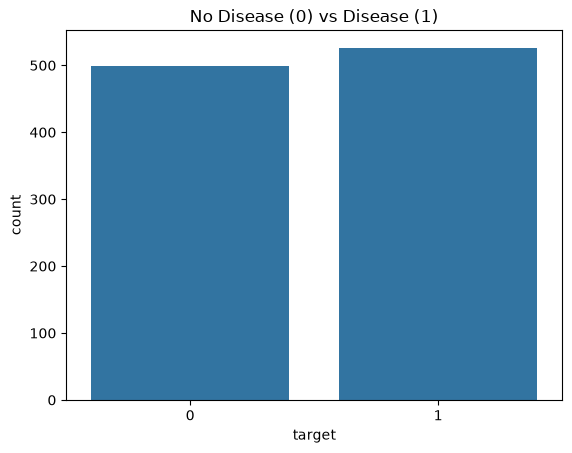

In [ ]:
# Balance chart
sns.countplot(x='target', data=df)
plt.title("No Disease (0) vs Disease (1)")
plt.savefig("chart_class_balance.png")
plt.show()

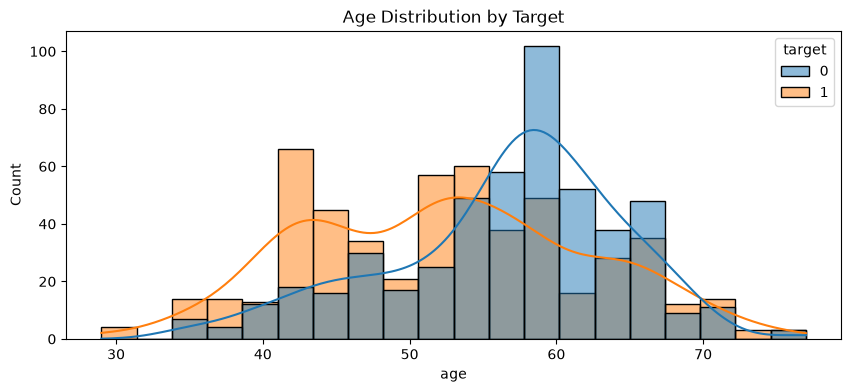


Age stats grouped by target:
        count       mean       std   min   25%   50%   75%   max
target                                                          
0       499.0  56.569138  7.908153  35.0  52.0  58.0  62.0  77.0
1       526.0  52.408745  9.631804  29.0  44.0  52.0  59.0  76.0


In [6]:
# Age distribution
plt.figure(figsize=(10, 4))
sns.histplot(data=df, x='age', hue='target', bins=20, kde=True)
plt.title("Age Distribution by Target")
plt.savefig("chart_age_distribution.png")
plt.show()
 
print("\nAge stats grouped by target:")
print(df.groupby('target')['age'].describe())

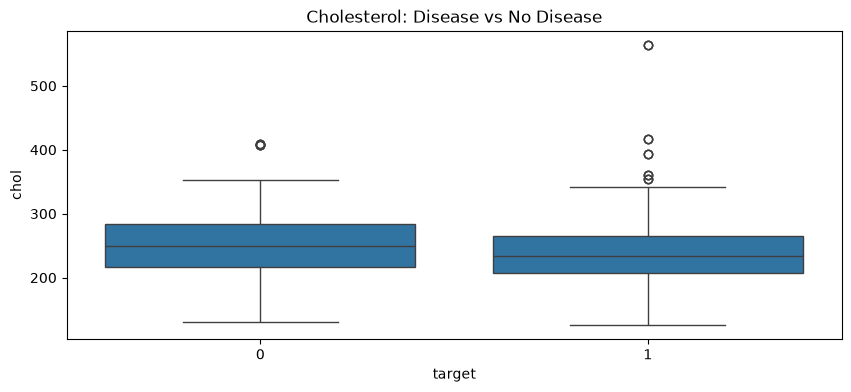


Cholesterol stats grouped by target:
        count        mean        std    min    25%    50%     75%    max
target                                                                  
0       499.0  251.292585  49.558924  131.0  217.0  249.0  284.00  409.0
1       526.0  240.979087  53.010345  126.0  208.0  234.0  265.75  564.0


In [7]:
# Cholesterol distribution
plt.figure(figsize=(10, 4))
sns.boxplot(x='target', y='chol', data=df)
plt.title("Cholesterol: Disease vs No Disease")
plt.savefig("chart_cholesterol_boxplot.png")
plt.show()
 
print("\nCholesterol stats grouped by target:")
print(df.groupby('target')['chol'].describe())

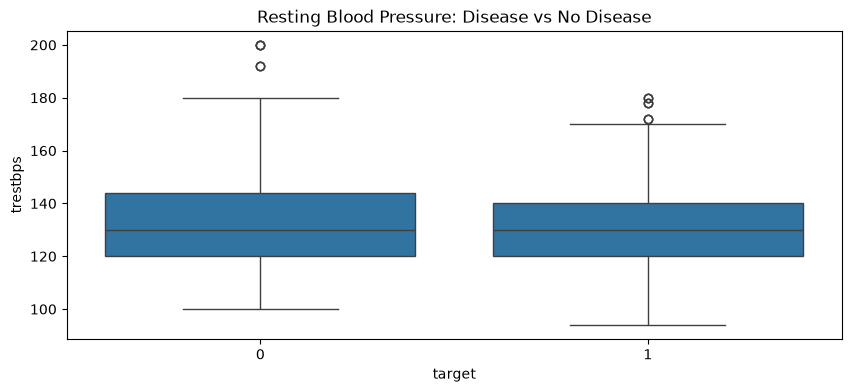

In [ ]:
# BP distribution 
plt.figure(figsize=(10, 4))
sns.boxplot(x='target', y='trestbps', data=df)
plt.title("Resting Blood Pressure: Disease vs No Disease")
plt.savefig("chart_bp_boxplot.png")
plt.show()

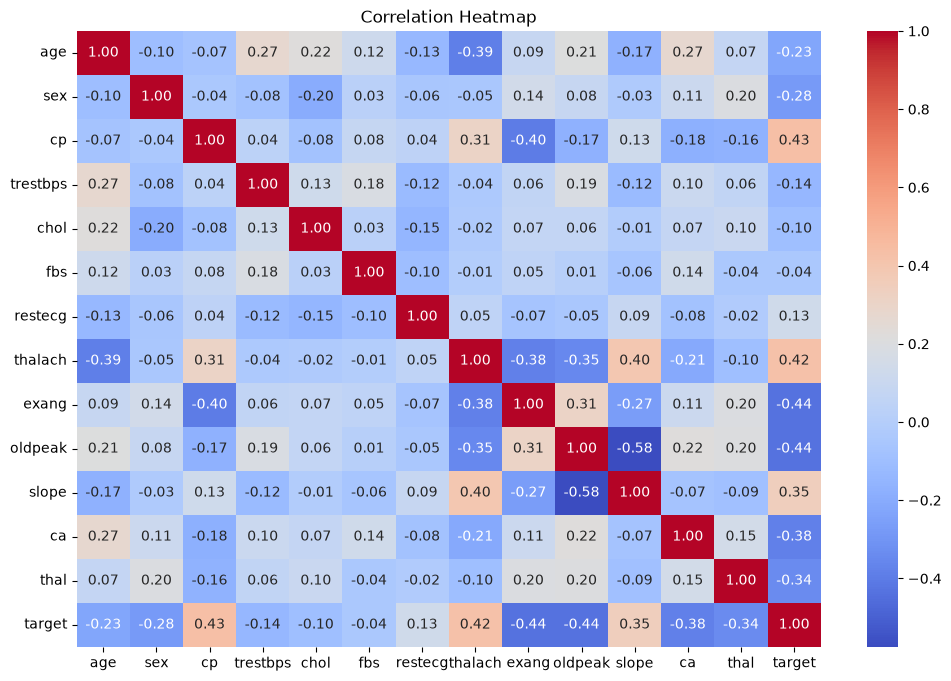

In [9]:
# Correl heatmap 
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.savefig("chart_correlation_heatmap.png")
plt.show()

In [11]:
# Summary 
disease_pct = df['target'].value_counts(normalize=True)[1] * 100
print(f"\nSUMMARY")
print(f"Total patients: {df.shape[0]}")
print(f"Disease percentage: {disease_pct:.1f}%")
print(f"Missing values: {df.isnull().sum().sum()}")
print("Charts saved: chart_class_balance.png, chart_age_distribution.png, "
      "chart_cholesterol_boxplot.png, chart_bp_boxplot.png, "
      "chart_correlation_heatmap.png")


SUMMARY
Total patients: 1025
Disease percentage: 51.3%
Missing values: 0
Charts saved: chart_class_balance.png, chart_age_distribution.png, chart_cholesterol_boxplot.png, chart_bp_boxplot.png, chart_correlation_heatmap.png


In [12]:
# Preprocessing
# Import Lib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pickle

In [23]:
print("Rows before removing duplicates:", len(df))

Rows before removing duplicates: 1025


In [24]:
# Removing Duplicates
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 302


In [26]:
# Scaling num cols
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
 
scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
 
with open("heart_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print("heart_scaler.pkl")

heart_scaler.pkl


In [27]:
# Separate X and Y Features  
X = df.drop('target', axis=1)
y = df['target']

In [28]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
 
print("\nTrain disease %:", round(y_train.value_counts(normalize=True)[1] * 100, 2))
print("Test disease %:", round(y_test.value_counts(normalize=True)[1] * 100, 2))
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train disease %: 54.36
Test disease %: 54.1
Train shape: (241, 13)
Test shape: (61, 13)


In [18]:
# Model Training
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [32]:
# Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)
 
print("Logistic Regression:")
print(classification_report(y_test, y_pred_log))

Logistic Regression:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [33]:
# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
 
print("Random Forest:")
print(classification_report(y_test, y_pred_rf))

Random Forest:
              precision    recall  f1-score   support

           0       0.74      0.71      0.73        28
           1       0.76      0.79      0.78        33

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



In [34]:
# Model Save 
import pickle

with open("heart_model.pkl", "wb") as f:
    pickle.dump(log_model, f)

print("Model saved as heart_model.pkl")

Model saved as heart_model.pkl
